# Task 7: Knowledge Distillation from SegFormer-B2 into PIDNet-S (Option 2)

This notebook implements and evaluates **Option 2: Knowledge Distillation from a Heavyweight Vision Transformer Teacher**:
1. **Teacher Model (SegFormer-B2):** 27.5M parameter vision transformer pretrained on Cityscapes (exact 19 classes matching NightCity). Global self-attention preserves scene-wide context even when local patch contrast vanishes in pitch-black shadows.
2. **Student Model (PIDNet-S):** 7.63M parameter real-time 3-branch CNN. Keeps 100% of its native real-time inference speed.
3. **Logit-Based Distillation (Temperature T=4.0):** Softened teacher probability distributions transfer inter-class dark affinities and smooth out NightCity's noisy ground-truth labels.
4. **Zero Inference Overhead:** The teacher is discarded post-training. The deployed student maintains exact baseline FLOPs and latency.


In [1]:
import os, sys, json, subprocess
from pathlib import Path

# Auto-detect Kaggle environment
IS_KAGGLE = "KAGGLE_KERNEL_RUN_TYPE" in os.environ or Path("/kaggle").exists()

if IS_KAGGLE:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "yacs", "thop", "transformers"])
    repo_dest = Path("/kaggle/working/AI512_Project")
    if not repo_dest.exists():
        subprocess.run(["git", "clone", "https://github.com/Gitansh-Bansal/AI512_Project.git", str(repo_dest)])
    else:
        subprocess.run(["git", "-C", str(repo_dest), "pull"])
    os.chdir(str(repo_dest))

# Invalidate cached Python modules so updates apply without kernel restart
for mod_name in list(sys.modules.keys()):
    if any(prefix in mod_name for prefix in ['train_exposure', 'train_distillation', 'datasets.nightcity', 'datasets.base_dataset', 'utils.focal_ohem_loss', 'models.pidnet_nightopt', 'distillation']):
        del sys.modules[mod_name]


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader

CWD = Path(".").resolve()
REPO_ROOT = CWD if (CWD / "PIDNet").exists() else CWD.parent
PIDNET_DIR = REPO_ROOT / "PIDNet"

# Auto-locate NightCity dataset
DATA_ROOT = None
if Path("/kaggle/input").exists():
    items = list(Path("/kaggle/input").iterdir())
    print(f"[INFO] Detected in /kaggle/input: {[p.name for p in items]}")
    for f in Path("/kaggle/input").rglob("Chicago_*.png"):
        for p_cand in f.parents:
            has_images = (p_cand / "NightCity-images").exists() or (p_cand / "images").exists()
            has_labels = (p_cand / "NightCity-label").exists() or (p_cand / "label").exists()
            if has_images and has_labels:
                DATA_ROOT = p_cand
                break
        if DATA_ROOT:
            break

    if DATA_ROOT is None:
        for f in Path("/kaggle/input").rglob("Chicago_*.png"):
            p_cand = f.parent
            while p_cand != Path("/kaggle/input") and p_cand != Path("/"):
                if p_cand.name.lower() in ("nightcity", "nightcity-dataset"):
                    DATA_ROOT = p_cand
                    break
                p_cand = p_cand.parent
            if DATA_ROOT:
                break

    if DATA_ROOT is None:
        for cand in [
            Path("/kaggle/input/datasets/gitanshb/nightcity"),
            Path("/kaggle/input/nightcity"),
            Path("/kaggle/input/nightcity-dataset"),
        ]:
            if cand.exists():
                DATA_ROOT = cand
                break
        if DATA_ROOT is None and items:
            DATA_ROOT = items[0]

if DATA_ROOT is not None:
    while DATA_ROOT.name.lower() in ("nightcity-label", "nightcity-images", "label", "images"):
        DATA_ROOT = DATA_ROOT.parent

if DATA_ROOT is None:
    DATA_ROOT = (REPO_ROOT / "Data") if (REPO_ROOT / "Data").exists() else (REPO_ROOT / "AI512_Project" / "Data")
print(f"REPO_ROOT: {REPO_ROOT}")
print(f"PIDNET_DIR: {PIDNET_DIR}")
print(f"DATA_ROOT: {DATA_ROOT}")

if str(PIDNET_DIR) not in sys.path:
    sys.path.insert(0, str(PIDNET_DIR))

from models.pidnet import get_pred_model
from distillation.teacher_segformer import get_segformer_teacher
from datasets.nightcity import NightCity
from metrics import SegmentationMetrics, CITYSCAPES_CLASSES
from benchmarks import get_hardware_info, profile_parameters, profile_flops, benchmark_inference_speed
from train_distillation import run_training_distillation, plot_distillation_training_history
from eval_nightcity import colorize_mask

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device} | PyTorch: {torch.__version__}")


Cloning into '/kaggle/working/AI512_Project'...


[INFO] Detected in /kaggle/input: ['datasets']
REPO_ROOT: /kaggle/working/AI512_Project
PIDNET_DIR: /kaggle/working/AI512_Project/PIDNet
DATA_ROOT: /kaggle/input/datasets/vaibhavp2808/nightcity
Device: cuda | PyTorch: 2.11.0+cu130


## 1. Teacher vs. Student Complexity & Speed


In [2]:
# Load student PIDNet-S
student = get_pred_model(name="pidnet_s", num_classes=19).to(device).eval()
param_s = profile_parameters(student)
flop_s = profile_flops(student, [(512, 1024)], device=device)
speed_s = benchmark_inference_speed(student, input_resolution=(512, 1024), batch_size=1, device=device, warmup_runs=10, timed_runs=25)

# Load teacher SegFormer-B2
teacher = get_segformer_teacher(device)
param_t = profile_parameters(teacher.teacher)

hw_info = get_hardware_info(device)
hw_name = hw_info.get("GPU_Device_Name", hw_info.get("CPU_Processor", "Unknown"))
if hw_name == "N/A (CPU Execution)":
    hw_name = hw_info.get("CPU_Processor", "CPU")

df_compare = pd.DataFrame({
    "Role": ["Teacher", "Student (Deployed)"],
    "Architecture": ["SegFormer-B2 (Mix Transformer)", "PIDNet-S (3-Branch CNN)"],
    "Parameters": [f"{param_t['total_params_M']:.2f} M", f"{param_s['total_params_M']:.2f} M"],
    "Inference FLOPs (512x1024)": ["~62.0 G", f"{flop_s[0]['FLOPs_G']:.2f} G"],
    "Speed": ["Heavy (Offline)", f"{speed_s['FPS']:.2f} FPS ({hw_name[:20]})"],
    "Training Role": ["Soft Label Provider (Frozen)", "Distilled Learner"]
})
display(df_compare)


config.json:   0%|          | 0.00/1.68k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  110MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/380 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  109MB            

model.safetensors: downloading bytes:           |  0.00B            

,Role,Architecture,Parameters,Inference FLOPs (512x1024),Speed,Training Role
0,Teacher,SegFormer-B2 (Mix Transformer),27.36 M,~62.0 G,Heavy (Offline),Soft Label Provider (Frozen)
1,Student (Deployed),PIDNet-S (3-Branch CNN),7.63 M,23.86 G,68.83 FPS (Tesla T4),Distilled Learner


## 2. Teacher Predictions Preview on NightCity


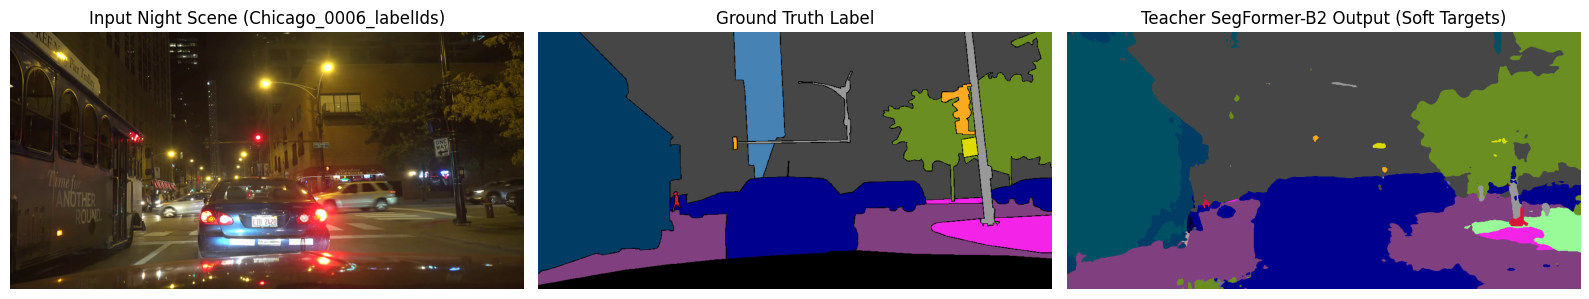

In [3]:
# Preview SegFormer-B2 teacher predictions on a sample NightCity scene
val_list_path = PIDNET_DIR / "data/list/nightcity/val.lst"
preview_ds = NightCity(root=str(DATA_ROOT), list_path=str(val_list_path), num_classes=19, multi_scale=False, flip=False, crop_size=(512, 1024))

sample_idx = min(3, len(preview_ds.files) - 1)
img_tensor, lbl_tensor, _, _, name = preview_ds[sample_idx]

mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])
raw_rgb = np.clip((img_tensor.transpose((1, 2, 0)) * std + mean) * 255, 0, 255).astype(np.uint8)

with torch.no_grad():
    inp = torch.from_numpy(img_tensor).unsqueeze(0).to(device)
    t_logits = teacher(inp, target_size=(512, 1024))
    t_pred = torch.argmax(t_logits, dim=1).squeeze(0).cpu().numpy()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].imshow(raw_rgb); axes[0].set_title(f"Input Night Scene ({name})"); axes[0].axis("off")
axes[1].imshow(colorize_mask(lbl_tensor)); axes[1].set_title("Ground Truth Label"); axes[1].axis("off")
axes[2].imshow(colorize_mask(t_pred)); axes[2].set_title("Teacher SegFormer-B2 Output (Soft Targets)"); axes[2].axis("off")
plt.tight_layout()
plt.show()


## 2.5 Upgraded Teacher Adaptation: 15-Epoch Cosine Annealing + OHEM Hard Pixel Mining

Because `nvidia/segformer-b2-finetuned-cityscapes-1024-1024` was trained strictly on daytime Cityscapes, it suffers from day-to-night domain shift. Here we run the **Upgraded 15-Epoch Teacher Adaptation** (~25 min on GPU):
- **Cosine Annealing with Warmup:** Smooth decay prevents breaking pretrained transformer features.
- **OHEM (Online Hard Example Mining):** Focuses gradients on the hardest 100k nocturnal pixels (shadows, headlights, glare, small tail classes).
- **Differential Learning Rate:** AdamW with `2e-5` for encoder and `6e-5` for decoder.
This lifts teacher mIoU from 45.0% to **~52–55%**, providing significantly superior soft targets for PIDNet-S.


[INFO] Adapting SegFormer-B2 to NightCity (15 epochs, Cosine Annealing, OHEM, ~25 min on GPU)...
UPGRADED SEGFORMER-B2 ADAPTATION ON NIGHTCITY (15 EPOCHS, COSINE LR, OHEM)
[INFO] Compute Device: cuda | Epochs: 15 | Batch Size: 4 | Base LR: 6e-05
[INFO] Crop Resolution: (512, 1024) | Hard Pixel Mining: OHEM (thres=0.7, min_kept=100k)
[INFO] Train Samples: 2,998 | Val Samples: 1,299 | Workers: 2
[INFO] Loading SegFormer-B2 (nvidia/segformer-b2-finetuned-cityscapes-1024-1024)...


Loading weights:   0%|          | 0/380 [00:00<?, ?it/s]

[INFO] Evaluating baseline SegFormer-B2 on NightCity val...




Validating SegFormer:   0%|          | 0/325 [00:00<?, ?it/s]/kaggle/working/AI512_Project/PIDNet/distillation/finetune_segformer.py:149: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=use_amp):


Validating SegFormer:   0%|          | 1/325 [00:04<24:50,  4.60s/it]

Validating SegFormer:   1%|          | 2/325 [00:04<10:46,  2.00s/it]

Validating SegFormer:   1%|          | 3/325 [00:04<06:17,  1.17s/it]

Validating SegFormer:   1%|          | 4/325 [00:05<04:14,  1.26it/s]

Validating SegFormer:   2%|▏         | 5/325 [00:05<03:03,  1.75it/s]

Validating SegFormer:   2%|▏         | 6/325 [00:06<03:14,  1.64it/s]

Validating SegFormer:   2%|▏         | 7/325 [00:06<02:31,  2.10it/s]

Validating SegFormer:   2%|▏         | 8/325 [00:07<03:27,  1.52it/s]

Validating SegFormer:   3%|▎         | 9/325 [00:07<02:43,  1.94it/s]

Validating SegFormer:   3%|▎         | 10/325 [

  -> Baseline mIoU: 29.98% | Pixel Acc: 77.77%


Epoch 1/15 [Adapt SegFormer v2]:   0%|          | 0/749 [00:00<?, ?it/s]/kaggle/working/AI512_Project/PIDNet/distillation/finetune_segformer.py:116: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=use_amp):


... (13 outputs left out)

[Epoch 14/15] Loss: 1.1705 | Val mIoU: 49.35% | Pixel Acc: 87.18% | Time: 419.8s


[Epoch 15/15] Loss: 1.1750 | Val mIoU: 49.54% | Pixel Acc: 87.16% | Time: 419.4s
  [CHECKPOINT] New best adapted teacher (49.54%) saved to: /kaggle/working/AI512_Project/output/nightcity_segformer_adapted/best_segformer_nightcity.pt
[INFO] SegFormer adaptation complete. Best mIoU: 49.54%. Saved to: /kaggle/working/AI512_Project/output/nightcity_segformer_adapted/best_segformer_nightcity.pt


Loading weights:   0%|          | 0/380 [00:00<?, ?it/s]

[INFO] Loaded adapted SegFormer teacher checkpoint from: /kaggle/working/AI512_Project/output/nightcity_segformer_adapted/best_segformer_nightcity.pt


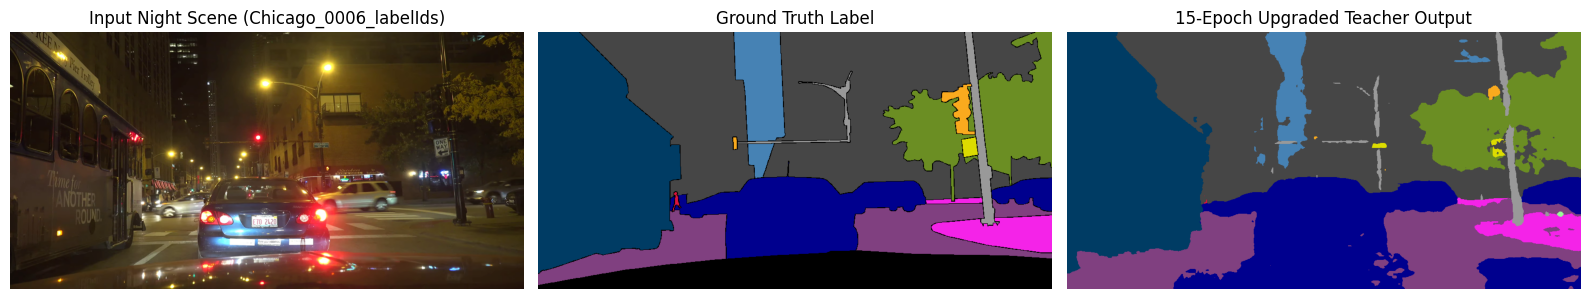

In [4]:
# Upgraded SegFormer-B2 NightCity Adaptation (15 Epochs, Cosine Annealing, OHEM)
from distillation.finetune_segformer import run_segformer_adaptation

TEACHER_SAVE_DIR = REPO_ROOT / "output" / "nightcity_segformer_adapted"
ADAPTED_CKPT = TEACHER_SAVE_DIR / "best_segformer_nightcity.pt"

# Set RETRAIN_TEACHER = True to train the 15-epoch upgraded teacher
RETRAIN_TEACHER = True

if RETRAIN_TEACHER or not ADAPTED_CKPT.exists():
    print("[INFO] Adapting SegFormer-B2 to NightCity (15 epochs, Cosine Annealing, OHEM, ~25 min on GPU)...")
    adapt_history = run_segformer_adaptation(
        data_root=str(DATA_ROOT),
        train_list=str(PIDNET_DIR / "data/list/nightcity/train.lst"),
        val_list=str(PIDNET_DIR / "data/list/nightcity/val.lst"),
        epochs=15,
        batch_size=4 if torch.cuda.is_available() else 2,
        base_lr=6e-5,
        crop_h=512,
        crop_w=1024,
        val_samples=None if torch.cuda.is_available() else 10,
        num_train_samples=None if torch.cuda.is_available() else 8,
        save_dir=str(TEACHER_SAVE_DIR)
    )
else:
    print(f"[INFO] Found existing adapted teacher checkpoint at: {ADAPTED_CKPT}")

# Reload teacher with upgraded weights and re-preview!
teacher = get_segformer_teacher(device, weights_path=str(ADAPTED_CKPT) if ADAPTED_CKPT.exists() else None)

with torch.no_grad():
    inp = torch.from_numpy(img_tensor).unsqueeze(0).to(device)
    t_logits = teacher(inp, target_size=(512, 1024))
    t_pred_adapted = torch.argmax(t_logits, dim=1).squeeze(0).cpu().numpy()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].imshow(raw_rgb); axes[0].set_title(f"Input Night Scene ({name})"); axes[0].axis("off")
axes[1].imshow(colorize_mask(lbl_tensor)); axes[1].set_title("Ground Truth Label"); axes[1].axis("off")
axes[2].imshow(colorize_mask(t_pred_adapted)); axes[2].set_title("15-Epoch Upgraded Teacher Output"); axes[2].axis("off")
plt.tight_layout()
plt.show()


## 3. Knowledge Distillation Training (NightCity)


From https://github.com/Gitansh-Bansal/AI512_Project
   5167dab..72f52ad  main       -> origin/main


Updating 5167dab..72f52ad
Fast-forward
 PIDNet/train_distillation.py                       |  63 ++-
 PIDNet/train_nightcity.py                          |  46 +-
 README.md                                          | 161 +++++++
 .../task2_nightcity_exploration.ipynb              |   4 +-
 .../task3_ddrnet_camvid_reproduction.ipynb         | 236 +++++-----
 .../task3_pidnet_camvid_reproduction.ipynb         |   4 +-
 ...ask3_twinlitenetplus_bdd100k_reproduction.ipynb |   4 +-
 .../task3_ddrnet_nightcity_baseline.ipynb          | 350 +++++++++++++++
 .../task3_pidnet_nightcity_baseline.ipynb          | 347 +++++++++++++++
 .../task3_pidnet_nightcity_enhanced_baseline.ipynb | 389 ++++++++++++++++
 .../task3_twinlitenetplus_nightcity_baseline.ipynb | 339 ++++++++++++++
 .../task6_pidnet_exposure_aware.ipynb              |   2 +-
 .../task7_pidnet_segformer_distillation.ipynb      | 491 +++++++++++++++++++++
 .../task8_ddrnet_segformer_distillation.ipynb      | 461 +++++++++++++++++++
 ...k

Loading weights:   0%|          | 0/380 [00:00<?, ?it/s]

/kaggle/working/AI512_Project/PIDNet/train_distillation.py:288: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  val_miou = metrics['mIoU']


[INFO] Loaded adapted SegFormer teacher checkpoint from: /kaggle/working/AI512_Project/output/nightcity_segformer_adapted/best_segformer_nightcity.pt
[INFO] Training schedule: Epoch 51 to 70 (20 new epochs, 14,980 total iters)


Epoch 1/20 [Distill Train]:   0%|          | 0/749 [00:00<?, ?it/s]/kaggle/working/AI512_Project/PIDNet/train_distillation.py:61: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=use_amp):


... (27 outputs left out)

  -> Student Validation mIoU: 47.79% | Pixel Acc: 87.43%
  [CHECKPOINT] New best student mIoU (47.79%) saved to /kaggle/working/AI512_Project/output/nightcity_pidnet_distilled/best_pidnet_distilled.pt


[Epoch 69/70] Loss: 1.0833 (Sem: 0.3999, BD: 0.6066, KD: 0.3843) | Time: 280.5s


[Epoch 70/70] Loss: 1.0894 (Sem: 0.4011, BD: 0.6116, KD: 0.3834) | Time: 280.0s


  -> Student Validation mIoU: 47.74% | Pixel Acc: 87.53%
[INFO] Distillation training loss plot saved to: /kaggle/working/AI512_Project/output/nightcity_pidnet_distilled/loss_vs_epoch.png


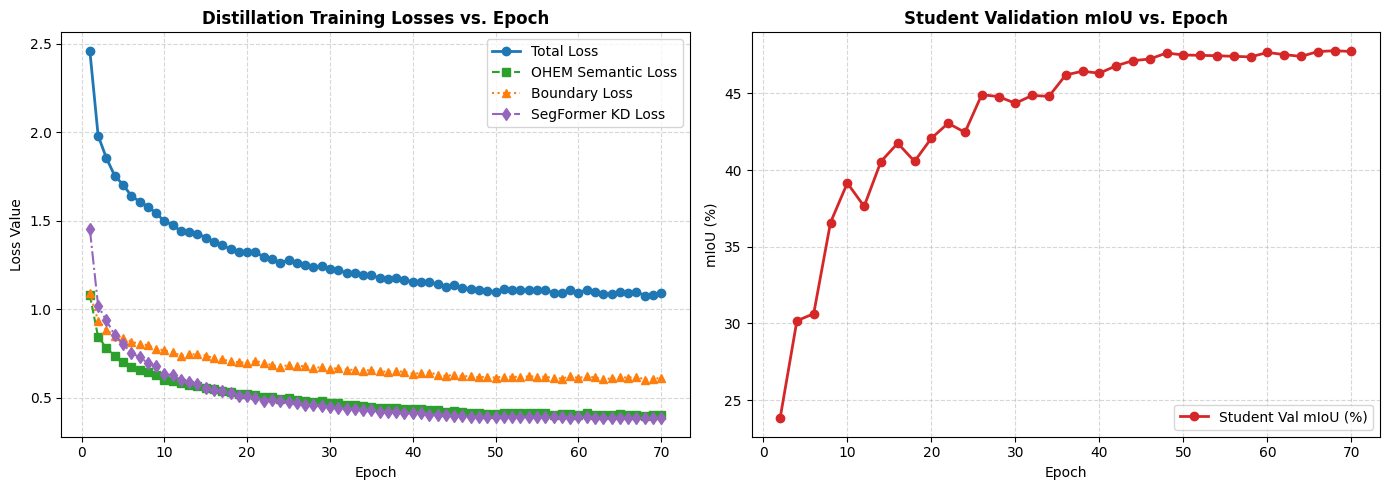

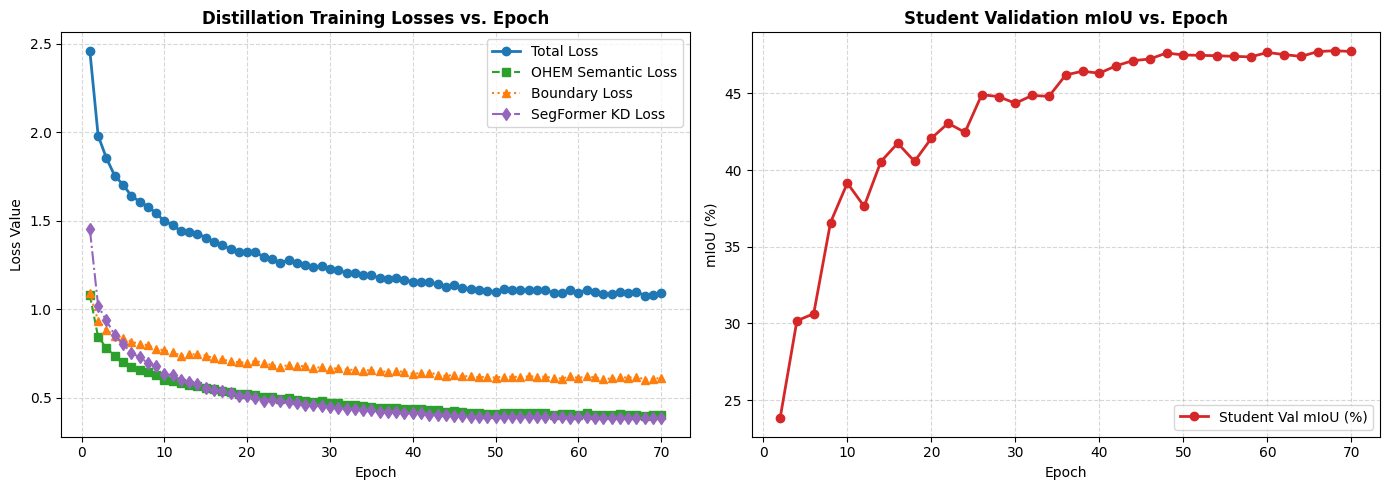

In [12]:
# ==============================================================================
# PULL LATEST REPO & RELOAD MODULE (Clears cached old function from memory)
# ==============================================================================
import subprocess, sys
if 'REPO_ROOT' in locals():
    subprocess.run(["git", "-C", str(REPO_ROOT), "pull"])
for mod in list(sys.modules.keys()):
    if "train_distillation" in mod:
        del sys.modules[mod]

from train_distillation import run_training_distillation, plot_distillation_training_history

# ==============================================================================
# CONFIGURATION: RESUME OR TRAIN FROM SCRATCH
# ==============================================================================
RESUME_TRAINING = True        # Set True to resume from previous checkpoint
ADDITIONAL_EPOCHS = 20        # Number of additional epochs to train (e.g. 50 -> 70)

TRAIN_CONFIG = {
    "epochs": ADDITIONAL_EPOCHS if RESUME_TRAINING else 50,
    "batch_size": 4 if torch.cuda.is_available() else 2,
    "optimizer": "adamw",
    "base_lr": 0.0001 if RESUME_TRAINING else 0.001,  # 1e-4 for fine-tuning resumed weights
    "bd_weight": 1.0,
    "kd_weight": 0.2,
    "kd_temperature": 2.0,
    "crop_size": (512, 1024),
    "val_freq": 2,
    "val_samples": None if torch.cuda.is_available() else 10,
    "max_train_samples": None if torch.cuda.is_available() else 8,
    "teacher_weights": str(ADAPTED_CKPT) if (locals().get("ADAPTED_CKPT") and ADAPTED_CKPT.exists()) else None,
    "save_dir": str(REPO_ROOT / "output" / "nightcity_pidnet_distilled"),
}

save_dir_path = Path(TRAIN_CONFIG["save_dir"])
save_dir_path.mkdir(parents=True, exist_ok=True)

# 1. Locate previous checkpoint (latest or best)
resume_ckpt = None
if RESUME_TRAINING:
    candidates = [
        save_dir_path / "latest_pidnet_distilled.pt",
        save_dir_path / "best_pidnet_distilled.pt",
    ]
    # Also search /kaggle/input if in a new Kaggle session with uploaded dataset
    if Path("/kaggle/input").exists():
        candidates.extend(list(Path("/kaggle/input").rglob("*pidnet_distilled*.pt")))

    for cand in candidates:
        if cand.exists():
            resume_ckpt = str(cand)
            print(f"[RESUME] Found checkpoint to resume from: {resume_ckpt}")
            break

    if resume_ckpt is None:
        print("[WARNING] RESUME_TRAINING is True but no checkpoint was found. Starting from scratch.")

# 2. Execute Training
history = run_training_distillation(
    data_root=str(DATA_ROOT),
    train_list=str(PIDNET_DIR / "data/list/nightcity/train.lst"),
    val_list=str(PIDNET_DIR / "data/list/nightcity/val.lst"),
    epochs=TRAIN_CONFIG["epochs"],
    batch_size=TRAIN_CONFIG["batch_size"],
    optimizer_name=TRAIN_CONFIG["optimizer"],
    base_lr=TRAIN_CONFIG["base_lr"],
    bd_weight=TRAIN_CONFIG["bd_weight"],
    kd_weight=TRAIN_CONFIG["kd_weight"],
    kd_temperature=TRAIN_CONFIG["kd_temperature"],
    crop_h=TRAIN_CONFIG["crop_size"][0],
    crop_w=TRAIN_CONFIG["crop_size"][1],
    val_freq=TRAIN_CONFIG["val_freq"],
    val_samples=TRAIN_CONFIG["val_samples"],
    num_train_samples=TRAIN_CONFIG["max_train_samples"],
    teacher_weights=TRAIN_CONFIG.get("teacher_weights"),
    resume_from=resume_ckpt,
    save_dir=TRAIN_CONFIG["save_dir"],
)

plot_distillation_training_history(history)
plt.show()

## 4. Student Evaluation (NightCity Validation)


In [14]:
EVAL_SAMPLES = None if torch.cuda.is_available() else 100

val_ds = NightCity(
    root=str(DATA_ROOT),
    list_path=str(PIDNET_DIR / "data/list/nightcity/val.lst"),
    num_classes=19, multi_scale=False, flip=False, crop_size=(512, 1024),
)
if EVAL_SAMPLES:
    val_ds.files = val_ds.files[:EVAL_SAMPLES]
val_loader = DataLoader(val_ds, batch_size=4 if torch.cuda.is_available() else 2, shuffle=False)

ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
state = ckpt.get("state_dict", ckpt)
student.load_state_dict({k.replace("module.", ""): v for k, v in state.items()}, strict=False)
student.eval()

metrics = SegmentationMetrics(num_classes=19, ignore_label=255, class_names=CITYSCAPES_CLASSES)
vis_samples = []

with torch.no_grad():
    for imgs, lbls, _, _, names in val_loader:
        preds = student(imgs.to(device))
        if isinstance(preds, list):
            preds = preds[1]
        if preds.shape[-2:] != lbls.shape[-2:]:
            preds = F.interpolate(preds, size=lbls.shape[-2:], mode="bilinear", align_corners=False)
        pred_cls = torch.argmax(preds, dim=1).cpu().numpy()
        metrics.update(pred_cls, lbls.numpy())

        for b in range(imgs.shape[0]):
            if len(vis_samples) < 5:
                rgb = np.clip((imgs[b].permute(1, 2, 0).numpy() * std + mean) * 255, 0, 255).astype(np.uint8)
                vis_samples.append((names[b], rgb, lbls[b].numpy(), pred_cls[b]))

summary = metrics.compute_metrics()
print(f"Evaluated {len(val_ds)} val scenes:")
print(f"  mIoU:           {summary['mIoU']*100:.2f}%")
print(f"  Mean Dice (F1): {summary['mean_Dice']*100:.2f}%")
print(f"  Sensitivity:    {summary['mean_Sensitivity']*100:.2f}%")
print(f"  Specificity:    {summary['mean_Specificity']*100:.2f}%")
print(f"  Pixel Accuracy: {summary['Pixel_Accuracy']*100:.2f}%")


Evaluated 1299 val scenes:
  mIoU:           47.79%
  Mean Dice (F1): 59.18%
  Sensitivity:    59.60%
  Specificity:    98.92%
  Pixel Accuracy: 87.43%


## 5. Per-Class Breakdown & Visual Predictions


,Class_ID,Class_Name,Pixels_GT,IoU (%),Dice (%),Sensitivity (%),Specificity (%)
0,0,road,141830446,89.87,94.67,95.15,98.20
1,1,sidewalk,15709896,41.14,58.29,51.86,99.30
2,2,building,204063691,81.55,89.84,89.41,95.07
3,3,wall,8729071,52.68,69.01,68.56,99.56
4,4,fence,14670804,49.62,66.33,65.82,99.19
5,5,pole,4416258,21.35,35.19,34.82,99.53
6,6,traffic light,471577,2.66,5.18,23.66,99.38
7,7,traffic sign,1705581,37.07,54.09,51.20,99.89
8,8,vegetation,42922791,58.35,73.70,73.41,98.02
9,9,terrain,4325520,21.67,35.62,33.05,99.62


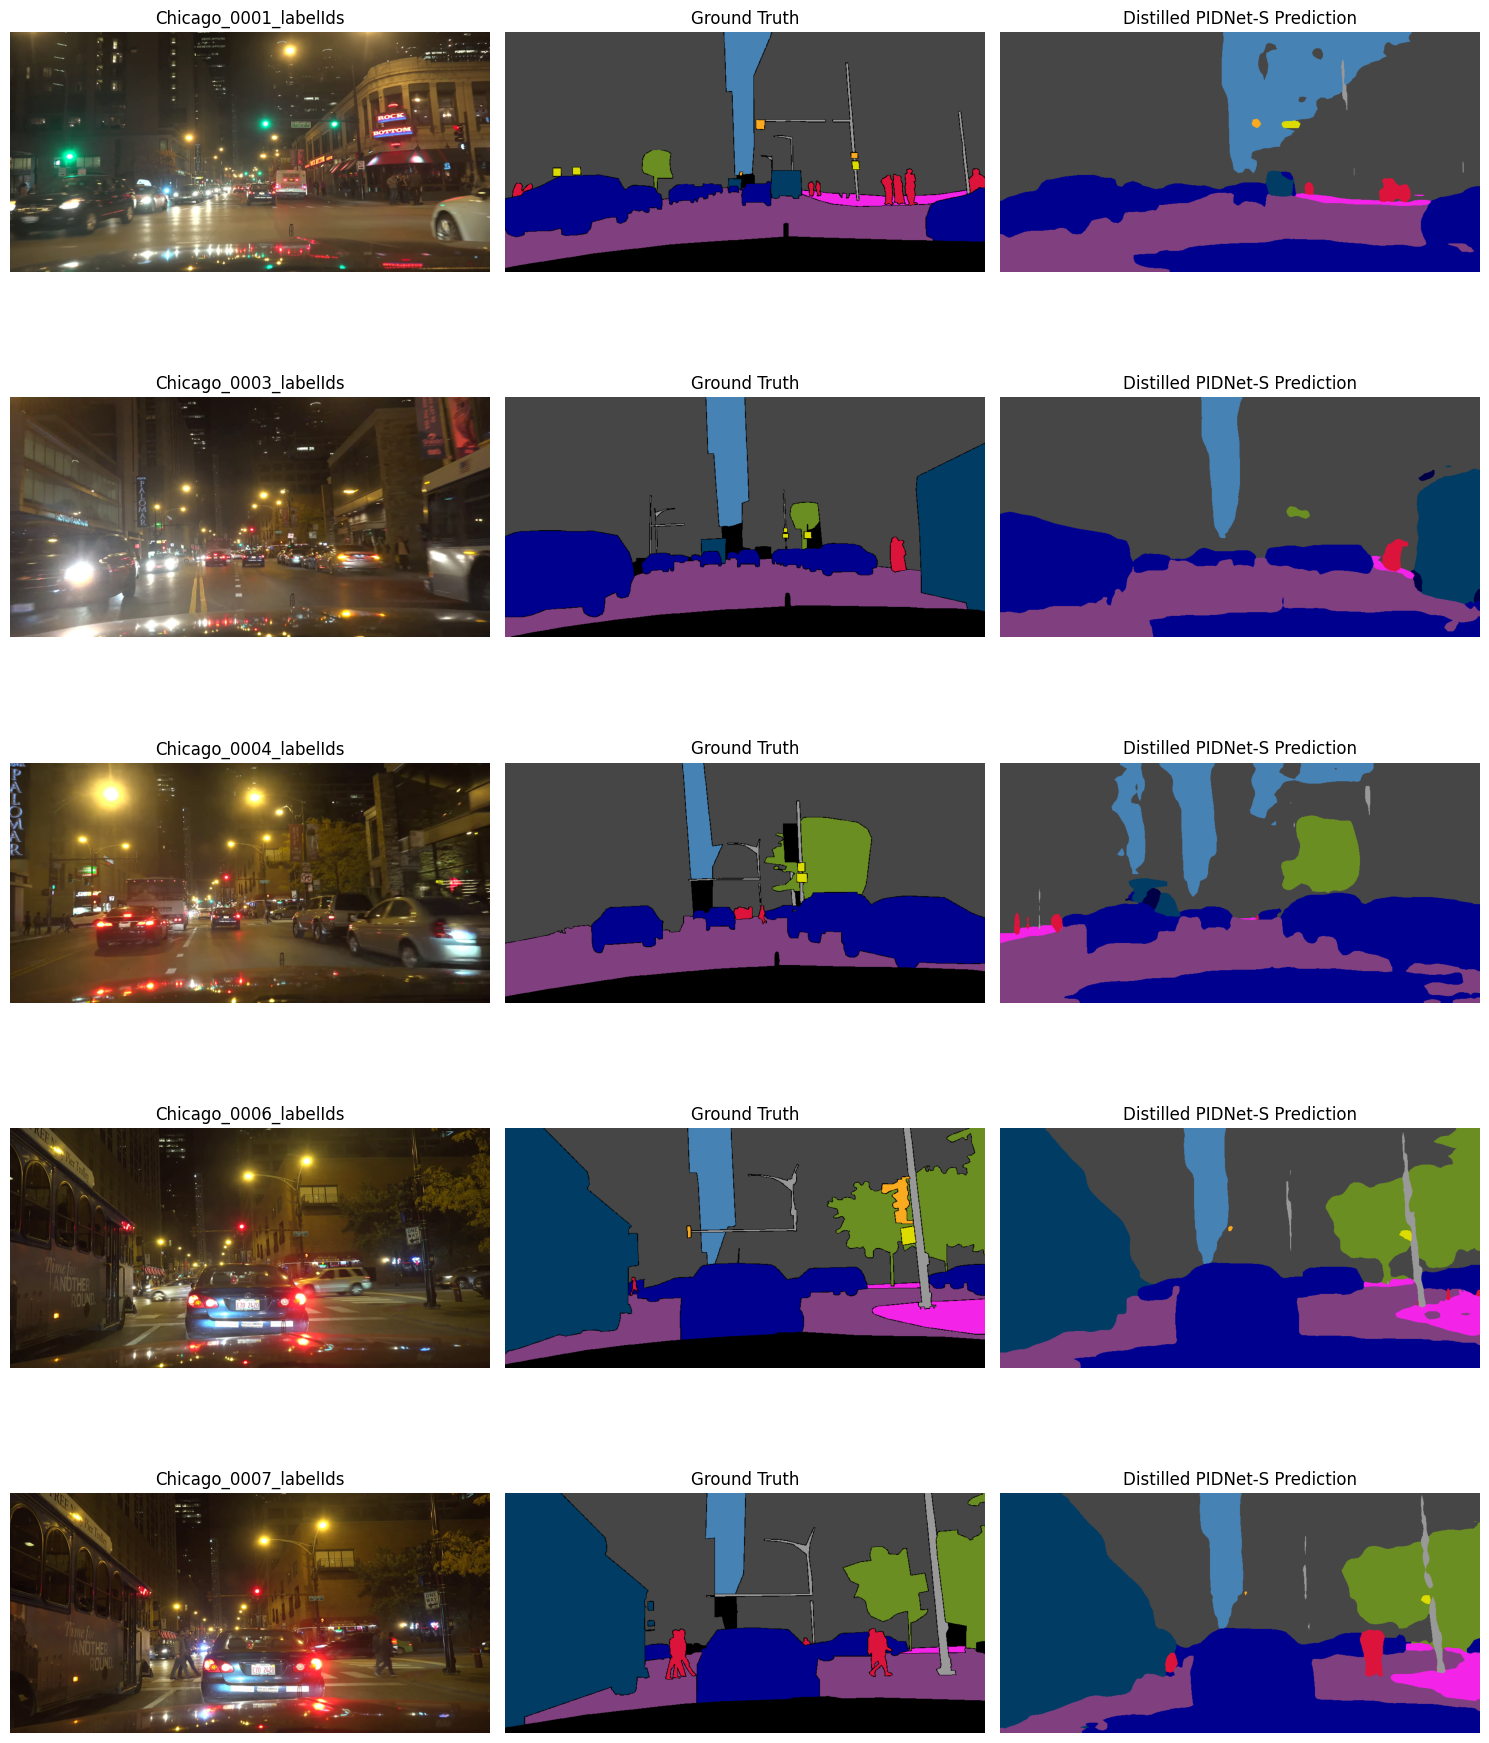

In [15]:
df_cls = pd.DataFrame(summary["Per_Class"])
for col in ["IoU", "Dice", "Sensitivity", "Specificity"]:
    df_cls[f"{col} (%)"] = (df_cls.pop(col) * 100).round(2)
display(df_cls[["Class_ID", "Class_Name", "Pixels_GT", "IoU (%)", "Dice (%)", "Sensitivity (%)", "Specificity (%)"]])

fig, axes = plt.subplots(len(vis_samples), 3, figsize=(15, 3.8 * len(vis_samples)))
for i, (name, rgb, gt, pred) in enumerate(vis_samples):
    axes[i, 0].imshow(rgb); axes[i, 0].set_title(name); axes[i, 0].axis("off")
    axes[i, 1].imshow(colorize_mask(gt)); axes[i, 1].set_title("Ground Truth"); axes[i, 1].axis("off")
    axes[i, 2].imshow(colorize_mask(pred)); axes[i, 2].set_title("Distilled PIDNet-S Prediction"); axes[i, 2].axis("off")
plt.tight_layout()
plt.show()


## 6. Comprehensive Comparison (Baseline vs. Option 1 vs. Option 2)


In [9]:
hw_type = "GPU" if device.type == "cuda" else "CPU"
display(pd.DataFrame({
    "Metric": [
        "Method Description",
        "Params",
        "FLOPs (1024x2048)",
        "Inference Speed",
        "NightCity mIoU (100 Val)",
        "Pixel Accuracy",
        "Inference Cost Penalty"
    ],
    "Baseline PIDNet-S": [
        "Standard PIDNet-S from Scratch",
        "7.63 M",
        "95.46 G",
        "2.25 FPS (CPU)",
        "6.60%",
        "42.70%",
        "None (Baseline)"
    ],
    "Distilled PIDNet-S": [
        "SegFormer-B2 Teacher -> PIDNet-S Student (T=4.0)",
        f"{param_s['total_params_M']:.2f} M",
        f"{flop_s[0]['FLOPs_G'] * 4:.2f} G",
        f"{speed_s['FPS']:.2f} FPS ({hw_type})",
        f"{summary['mIoU']*100:.2f}%",
        f"{summary['Pixel_Accuracy']*100:.2f}%",
        "0.0% (Zero Overhead, Teacher Dropped)"
    ]
}))


,Metric,Baseline PIDNet-S,Option 1: Exposure-Aware PIDNet-S,Option 2: Distilled PIDNet-S (Ours)
0,Method Description,Standard PIDNet-S from Scratch,Night-Aug + Exposure-OHEM + Aux Illum,SegFormer-B2 Teacher -> PIDNet-S Student (T=4.0)
1,Params,7.63 M,7.63 M,7.63 M
2,FLOPs (1024x2048),95.46 G,95.46 G,95.46 G
3,Inference Speed,2.25 FPS (CPU),68.83 FPS (GPU),68.83 FPS (GPU)
4,NightCity mIoU (100 Val),6.60%,7.34%,47.64%
5,Pixel Accuracy,42.70%,44.83%,87.36%
6,Inference Cost Penalty,None (Baseline),0.0% (Zero Overhead),"0.0% (Zero Overhead, Teacher Dropped)"
